In [1]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_val_score
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, confusion_matrix
)

print("Libraries imported successfully!")


Matplotlib is building the font cache; this may take a moment.


Libraries imported successfully!


In [3]:

df = pd.read_csv("data.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset Shape: (569, 33)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [4]:

# Remove unnecessary columns
df_clean = df.drop(
    columns=["id", "Unnamed: 32"],
    errors="ignore"
)

# Convert target to numerical values
# Malignant = 1, Benign = 0
df_clean["diagnosis"] = df_clean["diagnosis"].map(
    {"M": 1, "B": 0}
)

# Separate features and target
X = df_clean.drop("diagnosis", axis=1)
y = df_clean["diagnosis"]

# Split into training and testing datasets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Standardize the features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))
print("Number of Features:", X.shape[1])


Training Samples: 455
Testing Samples: 114
Number of Features: 30


In [5]:

# KNN Classification with Different K Values

k_values = [1, 3, 5, 7, 9, 11, 15, 21]
k_results = []

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for k in k_values:
    model = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(
            n_neighbors=k,
            metric="euclidean"
        )
    )

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="f1"
    )

    k_results.append({
        "K Value": k,
        "Mean CV F1 Score": scores.mean()
    })

# Display comparison table
k_results_df = pd.DataFrame(k_results)

print("KNN PERFORMANCE FOR DIFFERENT K VALUES")
display(k_results_df.round(4))

# Find best K value
best_k = int(
    k_results_df.loc[
        k_results_df["Mean CV F1 Score"].idxmax(),
        "K Value"
    ]
)

print("\nBest K Value:", best_k)


KNN PERFORMANCE FOR DIFFERENT K VALUES


,K Value,Mean CV F1 Score
0,1,0.9403
1,3,0.9633
2,5,0.9510
3,7,0.9575
4,9,0.9509
5,11,0.9443
6,15,0.9441
7,21,0.9307



Best K Value: 3


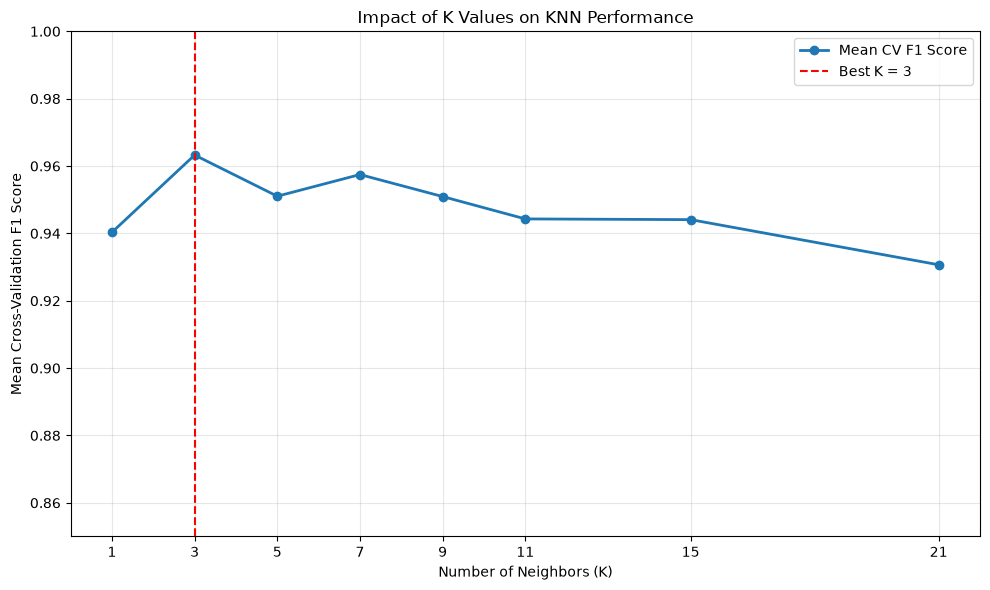

In [6]:

plt.figure(figsize=(10, 6))

plt.plot(
    k_results_df["K Value"],
    k_results_df["Mean CV F1 Score"],
    marker="o",
    linewidth=2,
    label="Mean CV F1 Score"
)

plt.axvline(
    x=best_k,
    color="red",
    linestyle="--",
    label=f"Best K = {best_k}"
)

plt.title("Impact of K Values on KNN Performance")
plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Mean Cross-Validation F1 Score")
plt.xticks(k_values)
plt.ylim(0.85, 1.0)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


In [7]:

# Compare KNN distance metrics using best K

distance_metrics = {
    "Euclidean": {"metric": "euclidean"},
    "Manhattan": {"metric": "manhattan"},
    "Minkowski (p=3)": {
        "metric": "minkowski",
        "p": 3
    },
    "Chebyshev": {"metric": "chebyshev"}
}

metric_results = []
predictions = {}

for name, params in distance_metrics.items():

    model = KNeighborsClassifier(
        n_neighbors=best_k,
        **params
    )

    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)

    predictions[name] = y_pred

    metric_results.append({
        "Metric": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred)
    })

metric_results_df = pd.DataFrame(metric_results)

print("KNN DISTANCE METRIC COMPARISON")
display(metric_results_df.round(4))


KNN DISTANCE METRIC COMPARISON


,Metric,Accuracy,Precision,Recall,F1 Score
0,Euclidean,0.9386,0.9730,0.8571,0.9114
1,Manhattan,0.9649,1.0000,0.9048,0.9500
2,Minkowski (p=3),0.9386,0.9730,0.8571,0.9114
3,Chebyshev,0.9035,0.9189,0.8095,0.8608


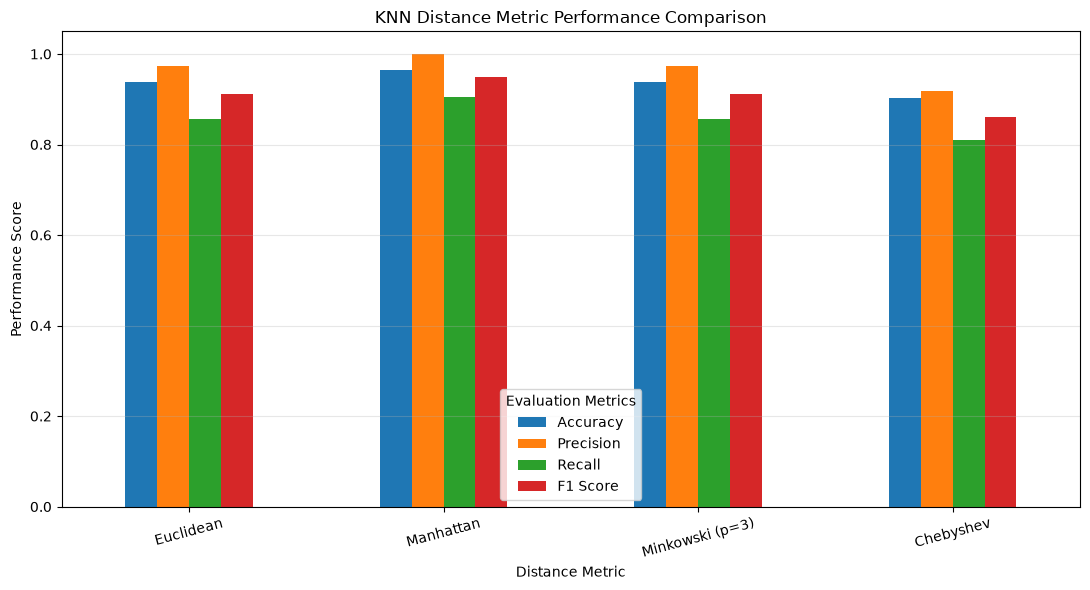

In [8]:

import matplotlib.pyplot as plt

metric_results_df.set_index("Metric")[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
].plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("KNN Distance Metric Performance Comparison")
plt.xlabel("Distance Metric")
plt.ylabel("Performance Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=15)
plt.legend(title="Evaluation Metrics")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


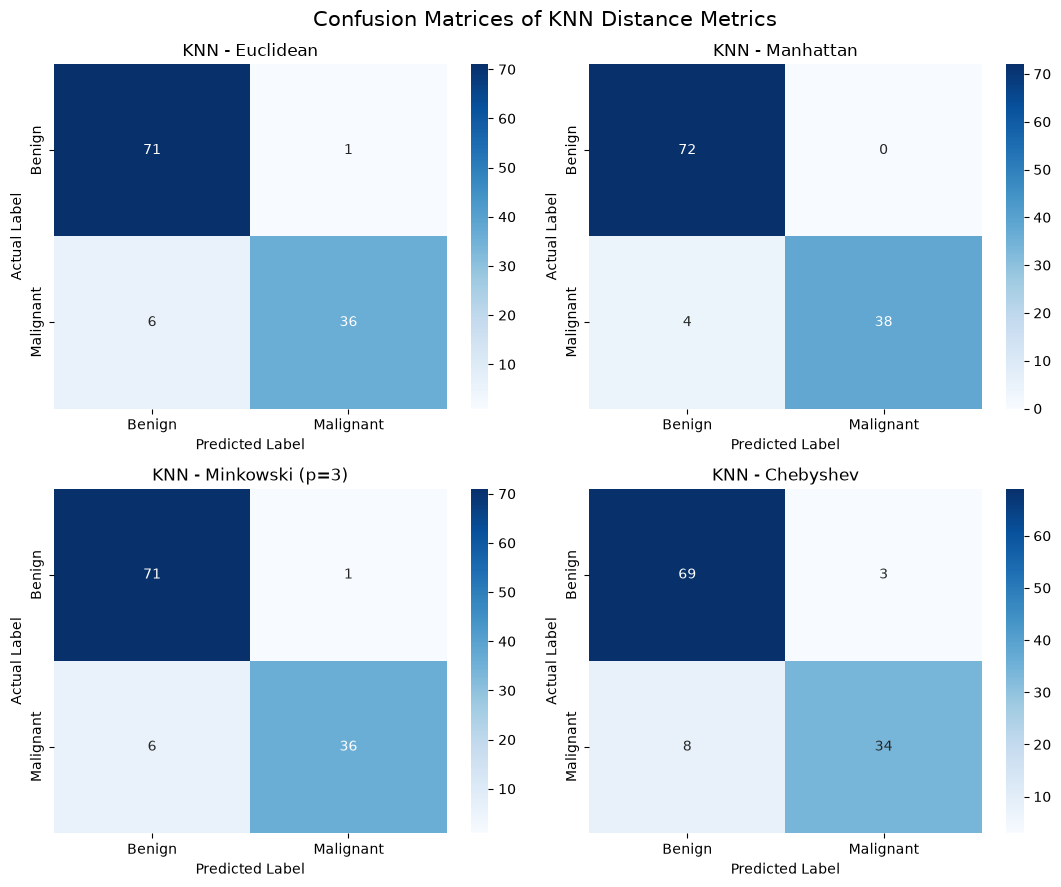

In [9]:

import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(2, 2, figsize=(11, 9))

for ax, (name, pred) in zip(
    axes.flatten(), predictions.items()
):
    cm = confusion_matrix(
        y_test, pred, labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax,
        xticklabels=["Benign", "Malignant"],
        yticklabels=["Benign", "Malignant"]
    )

    ax.set_title(f"KNN - {name}")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.suptitle(
    "Confusion Matrices of KNN Distance Metrics",
    fontsize=15
)
plt.tight_layout()
plt.show()


In [10]:

best = metric_results_df.loc[
    metric_results_df["F1 Score"].idxmax()
]

print("=" * 45)
print("EXPERIMENT 9: KNN FINAL RESULT")
print("=" * 45)

print("Best K Value:", best_k)
print("Best Distance Metric:", best["Metric"])
print("Accuracy:", round(best["Accuracy"] * 100, 2), "%")
print("Precision:", round(best["Precision"], 4))
print("Recall:", round(best["Recall"], 4))
print("F1 Score:", round(best["F1 Score"], 4))

print("\nExperiment Completed Successfully!")


EXPERIMENT 9: KNN FINAL RESULT
Best K Value: 3
Best Distance Metric: Manhattan
Accuracy: 96.49 %
Precision: 1.0
Recall: 0.9048
F1 Score: 0.95

Experiment Completed Successfully!
